<a href="https://colab.research.google.com/github/auliarski/multimodal-cf-fuzzy/blob/main/Paddy_Doctor_Multimodal_CF_Fuzzy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Paddy Doctor: Deep Learning Multimodal (Citra + Umur + Varietas) → Sistem Pakar CF + Fuzzy
Notebook ini membangun **tiga model** untuk klasifikasi penyakit padi dari dataset **Paddy Doctor** (10 kelas), lalu menyambungkan hasilnya ke sistem pakar **Certainty Factor + Fuzzy Sugeno** untuk rekomendasi pupuk & perawatan.

| Model | Masukan | Tujuan |
|---|---|---|
| `meta` | umur + varietas saja | mengukur seberapa banyak label "bocor" lewat metadata |
| `image` | citra saja (CNN transfer learning) | acuan kinerja visual |
| `fusion` | citra + umur + varietas | model multimodal |

```
foto daun ─► CNN (EfficientNetB0 / MobileNetV2) ─┐
umur, varietas ─► embedding + MLP ───────────────┴─► klasifikasi 10 kelas ─► Grad-CAM (penjelasan)
                                                         │
                         probabilitas 4 penyakit target ─┘
gejala (opsional) + cuaca + umur ─► CF ─► Fuzzy Sugeno ─► dosis pupuk, perawatan, alasan
```

**Cara pakai di Google Colab:** *Runtime → Change runtime type → GPU (T4)*, lalu jalankan sel dari atas. Sumber data default memakai mirror Hugging Face (tanpa akun Kaggle).

> **Catatan jujur.** Kode ini saya uji hingga tuntas pada **data sintetis kecil** (hanya untuk memastikan alurnya berjalan), **bukan** pada data Paddy Doctor asli. Skema mirror Hugging Face (kolom `image, label, variety, age`) saya ketahui dari pratinjau halamannya; sel pemeriksa skema di Bab 2 akan memberi tahu jika berbeda. Angka kinerja nyata baru muncul setelah Anda menjalankannya dengan data asli.

In [ ]:
import os, sys, json, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import HistGradientBoostingClassifier
warnings.filterwarnings("ignore")
try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = lambda x, **k: x

if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", "install -q datasets")

import tensorflow as tf, keras
from keras import layers
assert int(keras.__version__.split(".")[0]) >= 3, "Notebook ini membutuhkan Keras 3 (TensorFlow >= 2.16)"
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

# ================= KONFIGURASI (ubah di sini) =================
CFG = dict(
    SUMBER="hf",
    HF_REPO="PawanKapakayala/paddy-disease-classification",
    KAGGLE_DIR="/content/paddy-disease",   # berisi train.csv dan train_images/<kelas>/<image_id>
    IMG=224, BATCH=32,
    MAX_PER_CLASS=None,           # mis. 300 untuk percobaan cepat; None = semua data
    BACKBONE="efficientnetb0",    # "efficientnetb0" | "mobilenetv2"
    PRETRAINED=True,              # bobot ImageNet (butuh internet)
    EPOCH_HEAD=4, EPOCH_FT=6, EPOCH_META=40,
    LR_HEAD=1e-3, LR_FT=1e-5, UNFREEZE_LAYERS=40,
    SEED=42, CACHE_DIR="/content/paddy_cache",
)
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); tf.random.set_seed(CFG["SEED"])
IMG = CFG["IMG"]

TensorFlow 2.21.0 | Keras 3.13.2 | GPU: []


## Bab 1 — Modul sistem pakar (CF + Fuzzy Sugeno)
Sel di bawah adalah modul yang sama dengan notebook *Sistem Pakar CF + Fuzzy* sebelumnya (4 penyakit: hawar daun bakteri, blas, bercak coklat, tungro). Ada satu penambahan: `rekomendasikan_cf` menerima CF yang sudah terhitung, sehingga **bukti dari model citra bisa ditambahkan** (Bab 7).
Basis pengetahuan (bobot CF, aturan fuzzy, dosis) masih rancangan awal yang perlu divalidasi pakar; dosis bersifat indikatif.

In [ ]:
BLB, BLAST, BS, TUN = "bacterial_leaf_blight", "leaf_blast", "brown_spot", "tungro"
PENYAKIT = [BLB, BLAST, BS, TUN]


CF_USER = {"tidak": 0.0, "ragu": 0.4, "cukup_yakin": 0.6, "yakin": 0.8, "sangat_yakin": 1.0}

# kode: (pertanyaan, {penyakit: CF pakar})  -- negatif = melemahkan
GEJALA = {
 "G01": ("Garis basah/kekuningan memanjang di tepi daun?",                 {BLB: 0.80}),
 "G02": ("Tepi/ujung daun mengering keabu-abuan seperti terbakar?",        {BLB: 0.60}),
 "G03": ("Pagi hari ada tetesan lendir kuning keruh pada daun sakit?",     {BLB: 0.70}),
 "G04": ("Daun muda layu menggulung & mati (kresek) pada tanaman muda?",   {BLB: 0.70}),
 "G05": ("Bercak berbentuk belah ketupat (lonjong, ujung runcing)?",       {BLAST: 0.80, BS: -0.30}),
 "G06": ("Bercak berpusat abu-abu keputihan dengan tepi coklat?",          {BLAST: 0.80}),
 "G07": ("Leher malai busuk coklat/patah, malai hampa?",                   {BLAST: 0.70}),
 "G08": ("Bercak bulat-oval coklat kecil tersebar di daun?",               {BS: 0.70}),
 "G09": ("Bercak dikelilingi lingkaran (halo) kuning?",                    {BS: 0.80, BLAST: -0.20}),
 "G10": ("Tanah kurang subur / tanaman tampak kurang hara?",               {BS: 0.50}),
 "G11": ("Tanaman sempat kekurangan air (lahan retak/kering)?",            {BS: 0.30}),
 "G12": ("Daun menguning-oranye dimulai dari ujung daun?",                 {TUN: 0.70}),
 "G13": ("Tanaman kerdil dan anakan sedikit?",                             {TUN: 0.80}),
 "G14": ("Ada wereng hijau di rumpun/lahan sekitar?",                      {TUN: 0.60}),
 "G15": ("Daun menguning merata TANPA bercak sama sekali?",                {TUN: 0.50, BS: -0.30, BLAST: -0.30}),
 "G16": ("Baru-baru ini memberi Urea dosis tinggi?",                       {BLB: 0.30, BLAST: 0.40}),
}

# bukti lingkungan (derajat keanggotaan fuzzy x CF pakar)
LINGKUNGAN = {
 "E01": ("Kelembapan udara tinggi", {BLB: 0.40, BLAST: 0.50}),
 "E02": ("Hujan lebat 7 hari terakhir", {BLB: 0.40, BLAST: 0.20}),
 "E03": ("Suhu sejuk (malam dingin)", {BLAST: 0.40}),
 "E04": ("Cuaca kering", {BS: 0.40}),
 "E05": ("Umur tanaman masih awal", {TUN: 0.40, BLB: 0.20}),
 "E06": ("Umur tanaman fase akhir", {BS: 0.30, BLAST: 0.30}),
}
print(len(GEJALA), "gejala,", len(LINGKUNGAN), "bukti lingkungan")

BASE_DOSE = {"Urea": 250, "SP-36": 100, "KCl": 100}   # kg/ha, indikatif

KB = {
 BLB: {"nama": "Hawar Daun Bakteri (Xanthomonas oryzae pv. oryzae)", "jenis_kimia": "Bakterisida",
   "ciri": "Garis basah kekuningan di tepi daun yang meluas dan mengering.",
   "pupuk": ["Kurangi Urea dan bagi 3 kali; N berlebih membuat jaringan lunak dan memicu penyakit.",
             "Naikkan KCl; kalium memperkuat jaringan dan menekan keparahan.",
             "Hentikan N susulan selama gejala aktif."],
   "budidaya": ["Pengairan berselang; jangan menggenang terus.",
                "Jangan alirkan air dari petak sakit ke petak sehat.",
                "Bersihkan gulma inang dan sisa jerami terinfeksi; bersihkan alat.",
                "Jajar legowo agar sirkulasi udara baik; musim depan pakai varietas tahan HDB."],
   "hayati": "Pseudomonas fluorescens atau Bacillus subtilis.",
   "kimia": "Bakterisida berbahan aktif tembaga (mis. tembaga hidroksida).",
   "pantangan": ["Jangan menambah Urea.", "Jangan menyemprot saat hujan/daun basah."]},
 BLAST: {"nama": "Blas Daun (Pyricularia oryzae / Magnaporthe oryzae)", "jenis_kimia": "Fungisida",
   "ciri": "Bercak belah ketupat berpusat abu-abu dengan tepi coklat; dapat menyerang leher malai.",
   "pupuk": ["Kurangi Urea dan bagi 3 kali; N berlebih sangat memicu blas.",
             "Naikkan KCl; pertimbangkan sumber silika (kompos jerami/abu sekam).",
             "Hindari pemupukan N susulan menjelang bunting-berbunga."],
   "budidaya": ["Tanam serempak dan gunakan varietas tahan blas.",
                "Perlakuan benih; hindari tanam terlalu rapat.",
                "Jaga pengairan tidak kekeringan; bersihkan gulma dan sisa tanaman sakit.",
                "Waspada blas leher malai saat berbunga bila cuaca lembap dan sejuk."],
   "hayati": "Trichoderma sp., Pseudomonas fluorescens, atau Bacillus subtilis.",
   "kimia": "Fungisida bahan aktif trisiklazol, isoprotiolan, atau azoksistrobin + difenokonazol.",
   "pantangan": ["Jangan memberi N berlebih.", "Jangan menunda penanganan saat cuaca lembap dan sejuk."]},
 BS: {"nama": "Bercak Coklat (Bipolaris oryzae)", "jenis_kimia": "Fungisida",
   "ciri": "Bercak oval coklat dengan halo kuning; terkait tanah miskin hara.",
   "pupuk": ["Penyakit erat dengan kekurangan hara: jangan kurangi N, penuhi dosis dasar.",
             "Tambah KCl; gunakan ZA sebagai sebagian sumber N bila tanah miskin belerang.",
             "Tambahkan bahan organik/kompos jerami (sumber silika)."],
   "budidaya": ["Jaga air tidak kekeringan.", "Bersihkan gulma dan sisa tanaman sakit.",
                "Perbaiki kesuburan tanah dengan bahan organik; musim depan pakai benih sehat."],
   "hayati": "Trichoderma sp. atau Bacillus subtilis (pencegahan).",
   "kimia": "Fungisida propikonazol, azoksistrobin + difenokonazol, atau mankozeb.",
   "pantangan": ["Jangan mengurangi pupuk dasar.", "Jangan membiarkan lahan kering saat pengisian."]},
 TUN: {"nama": "Tungro (virus, ditularkan wereng hijau)", "jenis_kimia": "Insektisida (pengendali vektor)",
   "ciri": "Daun menguning-oranye dari ujung, tanaman kerdil, anakan sedikit.",
   "pupuk": ["Virus TIDAK bisa disembuhkan pupuk; pupuk hanya membantu anakan sehat.",
             "Pemupukan berimbang; jangan N berlebih (tanaman rimbun menarik wereng).",
             "KCl cukup untuk ketahanan tanaman."],
   "budidaya": ["Cabut dan benamkan/musnahkan rumpun bergejala sedini mungkin.",
                "Tanam serempak dan atur pergiliran varietas tahan tungro sesuai anjuran BPTP.",
                "Pantau populasi wereng hijau (jaring ayun/lampu); bersihkan gulma inang.",
                "Hindari tanam bertahap yang menjaga sumber virus tetap ada."],
   "hayati": "Konservasi musuh alami wereng (laba-laba, kumbang predator); hindari semprot tak perlu.",
   "kimia": "Insektisida pengendali wereng hijau (mis. imidakloprid/tiametoksam/buprofezin) sesuai rekomendasi POPT/BPTP.",
   "pantangan": ["Jangan menunda eradikasi rumpun sakit.", "Jangan memberi Urea berlebih."]},
}

UMUM_TIDAK_PASTI = [
 "Terapkan pengairan berselang dan sanitasi lahan (aman untuk semua kasus).",
 "Jangan menambah Urea sampai diagnosis pasti.",
 "Pertahankan pemupukan K (KCl) sesuai dosis dasar.",
 "Jangan menyemprot pestisida dulu.",
 "Periksa ulang gejala di beberapa rumpun dan konsultasikan ke penyuluh/POPT/BPTP.",
]

def fase_tumbuh(hst):
    if hst <= 14: return "awal_vegetatif"
    if hst <= 40: return "anakan_aktif"
    if hst <= 60: return "primordia_bunting"
    if hst <= 85: return "berbunga_pengisian"
    return "pemasakan"

FASE_NOTE = {
 "awal_vegetatif": "Fase awal: fokus sanitasi dan pengairan; pupuk dasar boleh diberikan.",
 "anakan_aktif": "Fase anakan: waktu tepat pupuk susulan sesuai faktor dosis.",
 "primordia_bunting": "Fase primordia: pemberian K penting; batasi N.",
 "berbunga_pengisian": "Fase berbunga/pengisian: JANGAN beri Urea. Fokus pengairan dan pengendalian penyakit.",
 "pemasakan": "Fase pemasakan: tidak perlu pupuk; pestisida tidak dianjurkan mendekati panen.",
}

def trap(x, a, b, c, d):
    """Trapesium (a<=b<=c<=d); segitiga bila b==c."""
    x = float(x)
    if x < a or x > d: return 0.0
    if b <= x <= c:    return 1.0
    if x < b:          return (x - a) / (b - a) if b > a else 1.0
    return (d - x) / (d - c) if d > c else 1.0

MF = {
 "kep":   {"ringan": lambda x: trap(x, 0, 0, 4, 10),   "sedang": lambda x: trap(x, 4, 12, 20, 30),
           "berat":  lambda x: trap(x, 20, 35, 100, 100)},
 "fase":  {"awal":   lambda x: trap(x, 0, 0, 25, 45),  "tengah": lambda x: trap(x, 30, 45, 55, 70),
           "akhir":  lambda x: trap(x, 55, 75, 150, 150)},
 "rh":    {"rendah": lambda x: trap(x, 0, 0, 60, 72),  "sedang": lambda x: trap(x, 62, 72, 80, 88),
           "tinggi": lambda x: trap(x, 80, 90, 100, 100)},
 "suhu":  {"sejuk":  lambda x: trap(x, 15, 15, 23, 27)},
 "hujan": {"rendah": lambda x: trap(x, 0, 0, 20, 50),  "sedang": lambda x: trap(x, 30, 70, 100, 150),
           "lebat":  lambda x: trap(x, 100, 150, 400, 400)},
}

# (kondisi, faktor_Urea, faktor_KCl, skor_kimia)
ATURAN = {
 BLB: [({"kep":"ringan"}, .80,1.30,.10), ({"kep":"sedang"}, .60,1.40,.50), ({"kep":"berat"}, .40,1.50,.90),
       ({"kep":"sedang","rh":"tinggi"}, .50,1.50,.80), ({"kep":"berat","rh":"tinggi"}, .30,1.50,.95),
       ({"fase":"akhir"}, 0.0,1.00,.30)],
 BLAST: [({"kep":"ringan"}, .80,1.30,.20), ({"kep":"sedang"}, .60,1.40,.60), ({"kep":"berat"}, .40,1.50,.90),
       ({"kep":"sedang","rh":"tinggi"}, .50,1.50,.85), ({"kep":"berat","rh":"tinggi"}, .30,1.50,.95),
       ({"fase":"akhir"}, 0.0,1.00,.50)],
 BS: [({"kep":"ringan"}, 1.0,1.20,.10), ({"kep":"sedang"}, 1.0,1.30,.50), ({"kep":"berat"}, 1.0,1.50,.85),
       ({"kep":"sedang","rh":"rendah"}, 1.0,1.40,.50), ({"fase":"akhir"}, 0.0,1.00,.20)],
 TUN: [({"kep":"ringan"}, .90,1.20,.30), ({"kep":"sedang"}, .80,1.20,.60), ({"kep":"berat"}, .70,1.20,.80),
       ({"fase":"awal","kep":"sedang"}, .80,1.20,.70), ({"fase":"akhir"}, 0.0,1.00,.10)],
}



THRESH_CF, THRESH_MARGIN = 0.50, 0.15

def gabung_mycin(daftar):
    pos = [c for c in daftar if c > 0]; neg = [-c for c in daftar if c < 0]
    cfp = 1 - np.prod([1 - c for c in pos]) if pos else 0.0
    cfn = 1 - np.prod([1 - c for c in neg]) if neg else 0.0
    den = 1 - min(cfp, cfn)
    return (cfp - cfn) / den if den > 1e-9 else 0.0

def derajat_lingkungan(suhu, rh, hujan, hst):
    return {"E01": MF["rh"]["tinggi"](rh), "E02": MF["hujan"]["lebat"](hujan), "E03": MF["suhu"]["sejuk"](suhu),
            "E04": min(MF["hujan"]["rendah"](hujan), 1 - MF["rh"]["tinggi"](rh)),
            "E05": MF["fase"]["awal"](hst), "E06": MF["fase"]["akhir"](hst)}

def hitung_cf(jawaban, suhu=None, rh=None, hujan=None, hst=None, pakai_lingkungan=True):
    """jawaban: {"G01": "yakin", ...} -> {penyakit: CF}"""
    bukti = {p: [] for p in PENYAKIT}
    for kode, level in jawaban.items():
        if kode not in GEJALA: raise KeyError(f"gejala tidak dikenal: {kode}")
        if level not in CF_USER: raise ValueError(f"jawaban tidak valid: {level}")
        u = CF_USER[level]
        if u == 0: continue
        for p, cf in GEJALA[kode][1].items(): bukti[p].append(cf * u)
    if pakai_lingkungan and None not in (suhu, rh, hujan, hst):
        for e, deg in derajat_lingkungan(suhu, rh, hujan, hst).items():
            if deg <= 0: continue
            for p, cf in LINGKUNGAN[e][1].items(): bukti[p].append(cf * deg)
    return {p: gabung_mycin(v) for p, v in bukti.items()}

def putuskan(cf):
    urut = sorted(cf.items(), key=lambda t: -t[1])
    (p1, c1), (p2, c2) = urut[:2]
    return {"top": p1, "cf_top": c1, "kedua": p2, "cf_kedua": c2, "yakin": bool(c1 >= THRESH_CF and (c1 - c2) >= THRESH_MARGIN)}



SHARPEN = 3   # penajaman bobot CF: w ~ CF^3 agar penyakit dominan lebih berpengaruh

def inferensi_sugeno(cf, keparahan, hst, rh):
    nilai = {"kep": keparahan, "fase": hst, "rh": rh}
    sw = sn = sk = sc = 0.0; jejak = []
    for p, daftar in ATURAN.items():
        bp = max(cf.get(p, 0.0), 0.0) ** SHARPEN
        if bp <= 0: continue
        for kond, fn, fk, kim in daftar:
            kekuatan = min(MF[v][l](nilai[v]) for v, l in kond.items())
            w = kekuatan * bp
            if w <= 1e-9: continue
            sw += w; sn += w * fn; sk += w * fk; sc += w * kim
            jejak.append((w, p, kond, fn, fk, kim))
    if sw == 0: return 1.0, 1.0, 0.0, []
    jejak.sort(key=lambda t: -t[0])
    return sn / sw, sk / sw, sc / sw, jejak

def rekomendasikan_cf(cf, suhu, rh, hujan7, hst, keparahan, luas_ha=1.0):
    d = putuskan(cf)
    fn, fk, skor, jejak = inferensi_sugeno(cf, keparahan, hst, rh)
    fase = fase_tumbuh(hst)
    if fase in ("berbunga_pengisian", "pemasakan"): fn = 0.0                 # pagar: tanpa Urea
    if (not d["yakin"]) or fase == "pemasakan": tingkat = "tidak diperlukan"
    elif skor >= .60: tingkat = "disarankan"
    elif skor >= .30: tingkat = "siaga (pantau 3 hari, tindak bila memburuk)"
    else: tingkat = "tidak diperlukan"
    dosis = {"Urea": round(BASE_DOSE["Urea"] * fn * luas_ha, 1),
             "SP-36": round(BASE_DOSE["SP-36"] * (0 if fn < .05 else 1) * luas_ha, 1),
             "KCl": round(BASE_DOSE["KCl"] * fk * luas_ha * (0 if fase == "pemasakan" else 1), 1)}
    catatan = []
    if tingkat == "disarankan" and hujan7 > 100:
        catatan.append("Curah hujan tinggi: semprot saat cerah dan hindari hujan dalam beberapa jam setelah penyemprotan.")
    return {**d, "cf": cf, "fase": fase, "faktor_urea": round(fn, 2), "faktor_kcl": round(fk, 2),
            "skor_kimia": round(skor, 2), "kimia": tingkat, "dosis_kg": dosis, "jejak": jejak[:4],
            "catatan": catatan, "input": dict(suhu=suhu, rh=rh, hujan7=hujan7, hst=hst, keparahan=keparahan, luas_ha=luas_ha)}

def format_laporan(h):
    i = h["input"]; L = ["=" * 66, "REKOMENDASI SISTEM PAKAR (CF + FUZZY SUGENO)", "=" * 66, "Keyakinan diagnosis (CF):"]
    L += [f"  {k:24s} {v:+.2f}" for k, v in sorted(h["cf"].items(), key=lambda t: -t[1])]
    L.append(f"Input: keparahan {i['keparahan']}%, {i['hst']} HST ({h['fase']}), RH {i['rh']}%, suhu {i['suhu']}°C, hujan7 {i['hujan7']} mm, lahan {i['luas_ha']} ha")
    L.append(FASE_NOTE[h["fase"]])
    if h["yakin"]:
        kb = KB[h["top"]]; L += ["", f"DIAGNOSIS: {kb['nama']}", f"Ciri: {kb['ciri']}"]
    else:
        L += ["", f"DIAGNOSIS: BELUM PASTI (kandidat: {h['top']} / {h['kedua']})"] + [f"  - {t}" for t in UMUM_TIDAK_PASTI]
    L += ["", f"DOSIS PERKIRAAN (indikatif): Urea x{h['faktor_urea']}, KCl x{h['faktor_kcl']}"] + [f"  {k:6s}: {v} kg" for k, v in h["dosis_kg"].items()]
    if h["yakin"]:
        kb = KB[h["top"]]
        L.append(f"{kb['jenis_kimia'].upper()}: {h['kimia']} (skor fuzzy {h['skor_kimia']})")
        L += ["", "PUPUK:"] + [f"  - {c}" for c in kb["pupuk"]] + ["PERAWATAN:"] + [f"  - {c}" for c in kb["budidaya"]]
        L.append(f"  Hayati: {kb['hayati']}")
        if h["kimia"] == "disarankan": L.append(f"  Kimia : {kb['kimia']}")
        L += ["PANTANGAN:"] + [f"  - {c}" for c in kb["pantangan"]]
    else:
        L.append(f"PESTISIDA: {h['kimia']}")
    L += [f"  * {c}" for c in h["catatan"]]
    L += ["", "ALASAN (aturan fuzzy terkuat):"] + [f"  w={w:.2f} [{p}] jika {k} -> Urea x{a}, KCl x{b}, kimia {c}" for w, p, k, a, b, c in h["jejak"]]
    L.append("\nDosis & pestisida indikatif; sesuaikan dengan uji tanah & anjuran penyuluh setempat.")
    return "\n".join(L)

16 gejala, 6 bukti lingkungan


## Bab 2 — Memuat dataset Paddy Doctor
Dataset: foto daun padi dari sawah nyata di Tamil Nadu, India, dengan metadata **varietas** dan **umur tanaman (hari)** per foto. Gambar diubah ukurannya ke `IMG×IMG` sekali saja lalu disimpan sebagai cache `.npy` agar pelatihan cepat.

* **`hf`** — mirror Hugging Face `PawanKapakayala/paddy-disease-classification` (salinan data kompetisi Kaggle).
* **`kaggle`** — unduh sendiri (`kaggle competitions download -c paddy-disease-classification`, perlu menyetujui aturan kompetisi), ekstrak ke `KAGGLE_DIR`.
* **`sintetis`** — data buatan kecil, **hanya untuk menguji bahwa kode berjalan**.

Periksa lisensi/ketentuan penggunaan dataset sebelum dipakai untuk publikasi, dan cantumkan sitasi: Petchiammal dkk., *Paddy Doctor* (arXiv:2205.11108).

In [ ]:
KELAS_PD = ["bacterial_leaf_blight", "bacterial_leaf_streak", "bacterial_panicle_blight", "blast",
            "brown_spot", "dead_heart", "downy_mildew", "hispa", "normal", "tungro"]

def _ambil_subset(meta):
    M = CFG["MAX_PER_CLASS"]
    if not M: return meta.index.values
    return np.sort(pd.concat([g.sample(min(len(g), M), random_state=CFG["SEED"]) for _, g in meta.groupby("label")]).index.values)

def muat_hf():
    from datasets import load_dataset
    ds = load_dataset(CFG["HF_REPO"], split="train")
    print(ds)
    kurang = {"image", "label", "variety", "age"} - set(ds.column_names)
    if kurang: raise KeyError(f"Kolom {sorted(kurang)} tidak ada di dataset; kolom tersedia: {ds.column_names}. "
                              "Gunakan SUMBER='kaggle' atau sesuaikan fungsi ini.")
    meta = ds.remove_columns(["image"]).to_pandas()
    for kol in ("label", "variety"):
        nama = getattr(ds.features[kol], "names", None)
        if nama: meta[kol] = meta[kol].map(lambda i: nama[i])
    idx = _ambil_subset(meta); X = np.zeros((len(idx), IMG, IMG, 3), np.uint8)
    for k, i in enumerate(tqdm(idx, desc="resize")):
        X[k] = np.asarray(ds[int(i)]["image"].convert("RGB").resize((IMG, IMG), Image.BILINEAR))
    return X, meta.loc[idx].reset_index(drop=True)[["label", "variety", "age"]]

def muat_kaggle():
    root = Path(CFG["KAGGLE_DIR"]); tr = pd.read_csv(root / "train.csv")
    kurang = {"image_id", "label", "variety", "age"} - set(tr.columns)
    if kurang: raise KeyError(f"train.csv tidak memiliki kolom {sorted(kurang)}")
    idx = _ambil_subset(tr); tr = tr.loc[idx].reset_index(drop=True)
    X = np.zeros((len(tr), IMG, IMG, 3), np.uint8)
    for k, r in enumerate(tqdm(tr.itertuples(), total=len(tr), desc="resize")):
        X[k] = np.asarray(Image.open(root / "train_images" / r.label / r.image_id).convert("RGB").resize((IMG, IMG), Image.BILINEAR))
    return X, tr[["label", "variety", "age"]]

def muat_sintetis(n_per_kelas=60):
    """Data buatan: HANYA untuk menguji alur kode. Tidak mewakili data nyata."""
    r = np.random.default_rng(CFG["SEED"]); X, baris = [], []
    warna = r.integers(40, 215, size=(len(KELAS_PD), 3))
    for ci, nm in enumerate(KELAS_PD):
        for _ in range(n_per_kelas):
            im = np.clip(np.ones((IMG, IMG, 3)) * warna[ci] + r.normal(0, 18, (IMG, IMG, 3)), 0, 255)
            for _ in range(r.integers(2, 6)):            # bercak acak
                y0, x0 = r.integers(0, IMG - 8, 2); im[y0:y0 + 6, x0:x0 + 6] = 255 - warna[ci]
            X.append(im.astype(np.uint8))
            baris.append((nm, f"V{(ci + r.integers(0, 3)) % 6}", int(np.clip(r.normal(45 + 3 * ci, 8), 30, 90))))
    return np.stack(X), pd.DataFrame(baris, columns=["label", "variety", "age"])

cache = Path(CFG["CACHE_DIR"]); cache.mkdir(parents=True, exist_ok=True)
tag = f"{CFG['SUMBER']}_{IMG}_{CFG['MAX_PER_CLASS']}"
if (cache / f"X_{tag}.npy").exists() and CFG["SUMBER"] != "sintetis":
    X = np.load(cache / f"X_{tag}.npy"); meta = pd.read_csv(cache / f"meta_{tag}.csv"); print("dari cache:", tag)
else:
    X, meta = {"hf": muat_hf, "kaggle": muat_kaggle, "sintetis": muat_sintetis}[CFG["SUMBER"]]()
    if CFG["SUMBER"] != "sintetis": np.save(cache / f"X_{tag}.npy", X); meta.to_csv(cache / f"meta_{tag}.csv", index=False)
meta["variety"] = meta["variety"].astype(str)
print("citra:", X.shape, "| metadata:", meta.shape); meta.head()

README.md:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

data/train-00000-of-00002-a929229f3aaf71(…): reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002-a929229f3aaf71(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-4c2a20b9469e90(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00001-of-00002-4c2a20b9469e90(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10407 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'label', 'variety', 'age'],
    num_rows: 10407
})


resize:   0%|          | 0/10407 [00:00<?, ?it/s]

citra: (10407, 224, 224, 3) | metadata: (10407, 3)


,label,variety,age
0,bacterial_leaf_blight,ADT45,45
1,bacterial_leaf_blight,ADT45,45
2,bacterial_leaf_blight,ADT45,45
3,bacterial_leaf_blight,ADT45,45
4,bacterial_leaf_blight,ADT45,45


In [ ]:
# ---- pemeriksaan skema & pengodean
assert len(X) == len(meta) and meta[["label", "variety", "age"]].notna().all().all(), "ada data kosong"
kelas = sorted(meta.label.unique()); K = len(kelas); k2i = {k: i for i, k in enumerate(kelas)}
var_names = sorted(meta.variety.unique()); V = len(var_names); v2i = {v: i for i, v in enumerate(var_names)}
Y = meta.label.map(k2i).values.astype("int32"); VAR = meta.variety.map(v2i).values.astype("int32"); AGE = meta.age.values.astype("float32")
print(f"{K} kelas: {kelas}\n{V} varietas: {var_names}\numur: {AGE.min():.0f}-{AGE.max():.0f} hari")
tak_dikenal = set(kelas) - set(KELAS_PD)
if tak_dikenal: print("[peringatan] nama kelas berbeda dari Paddy Doctor standar:", tak_dikenal, "-> periksa pemetaan di Bab 7")

10 kelas: ['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight', 'blast', 'brown_spot', 'dead_heart', 'downy_mildew', 'hispa', 'normal', 'tungro']
10 varietas: ['ADT45', 'AndraPonni', 'AtchayaPonni', 'IR20', 'KarnatakaPonni', 'Onthanel', 'Ponni', 'RR', 'Surya', 'Zonal']
umur: 45-82 hari


## Bab 3 — Eksplorasi data & uji "kebocoran" metadata
Metadata (umur, varietas) bisa berkorelasi kuat dengan label karena cara data dikumpulkan (mis. penyakit tertentu hanya difoto pada varietas/umur tertentu). Jika demikian, model bisa "menebak" tanpa melihat penyakitnya. Karena itu ada model `meta` sebagai pembanding.

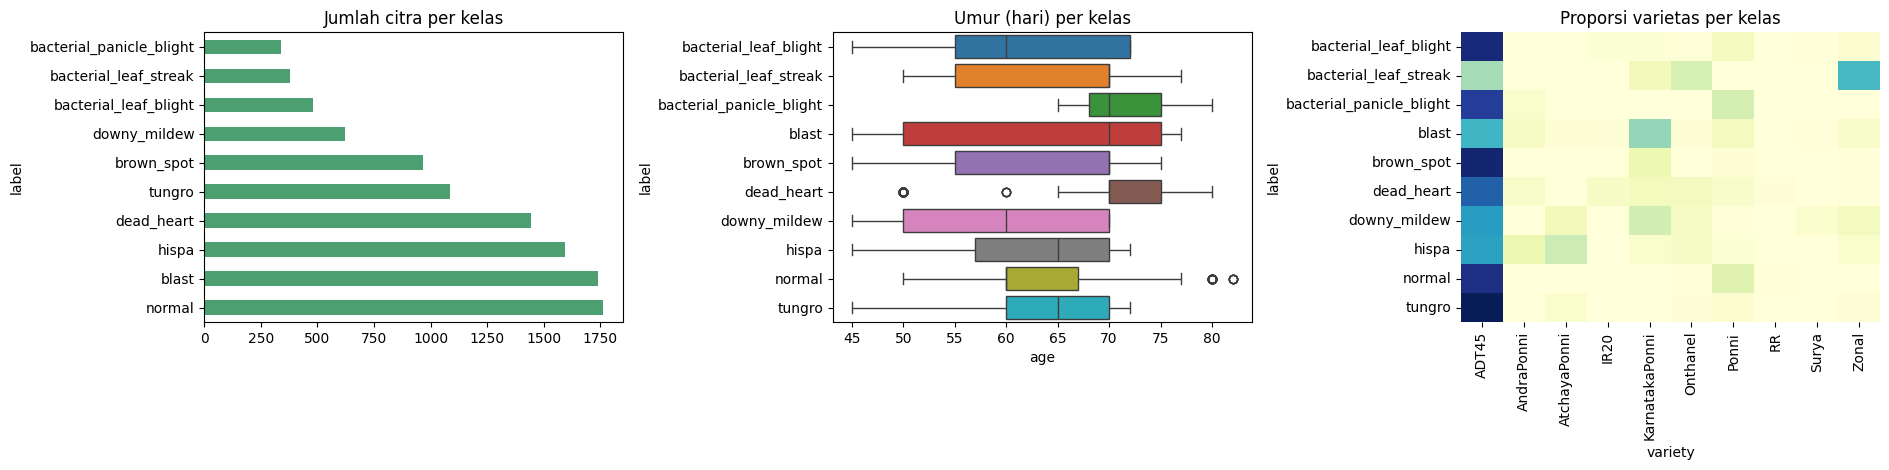

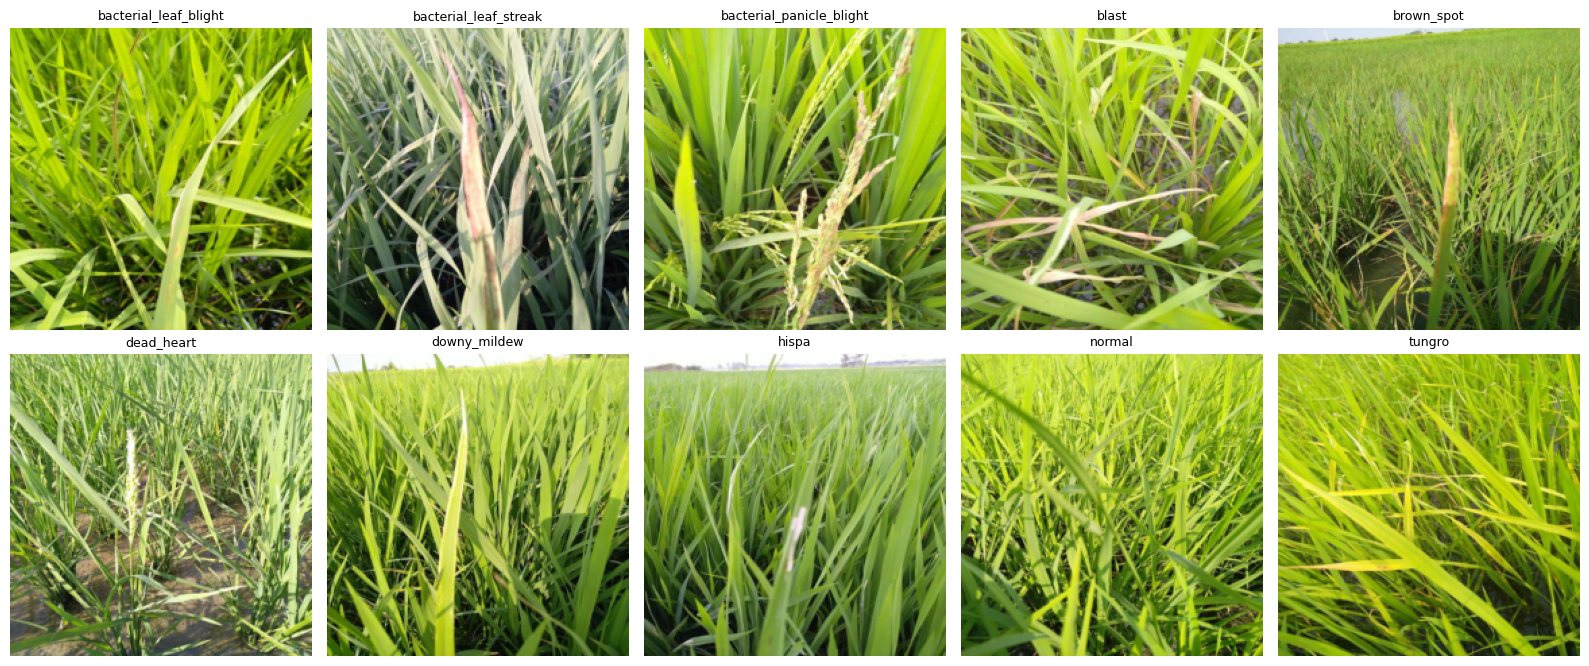

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
meta.label.value_counts().plot.barh(ax=ax[0], color="#4c9f70"); ax[0].set_title("Jumlah citra per kelas")
sns.boxplot(data=meta, y="label", x="age", ax=ax[1], orient="h", hue="label", legend=False); ax[1].set_title("Umur (hari) per kelas")
ct = pd.crosstab(meta.label, meta.variety, normalize="index"); sns.heatmap(ct, cmap="YlGnBu", ax=ax[2], cbar=False)
ax[2].set_title("Proporsi varietas per kelas"); plt.tight_layout(); plt.show()

n = min(K, 10); fig, ax = plt.subplots(2, 5, figsize=(16, 6.8))
for a, kl in zip(ax.ravel(), kelas[:n]):
    a.imshow(X[np.where(Y == k2i[kl])[0][0]]); a.set_title(kl, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Baseline hanya-metadata (validasi silang 5-lipat) vs. tebakan kelas mayoritas
F = np.c_[VAR, AGE]
gb = HistGradientBoostingClassifier(categorical_features=[True, False], random_state=CFG["SEED"], max_iter=150)
cv = StratifiedKFold(5, shuffle=True, random_state=CFG["SEED"])
acc_meta = cross_val_score(gb, F, Y, cv=cv, scoring="accuracy").mean()
f1_meta = cross_val_score(gb, F, Y, cv=cv, scoring="f1_macro").mean()
mayoritas = np.bincount(Y).max() / len(Y)
print(f"Tebakan kelas mayoritas : akurasi {mayoritas:.3f}")
print(f"Hanya umur + varietas   : akurasi {acc_meta:.3f} | macro-F1 {f1_meta:.3f}")
print("-> makin jauh di atas mayoritas, makin besar sinyal label yang bisa diambil model dari metadata saja.")

Tebakan kelas mayoritas : akurasi 0.170
Hanya umur + varietas   : akurasi 0.440 | macro-F1 0.352
-> makin jauh di atas mayoritas, makin besar sinyal label yang bisa diambil model dari metadata saja.


## Bab 4 — Pembagian data, pengodean, dan bobot kelas
Pembagian stratifikasi **70 / 15 / 15** (latih / validasi / uji). Umur distandarkan dengan statistik data latih. Bobot kelas menyeimbangkan kelas langka.

⚠️ Dataset tidak menyertakan ID tanaman/daun, sehingga foto yang sangat mirip dari tanaman yang sama bisa jatuh ke latih dan uji sekaligus; akurasi uji bisa sedikit terlalu optimistis.

In [ ]:
idx_all = np.arange(len(Y))
idx_tr, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=Y, random_state=CFG["SEED"])
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=Y[idx_tmp], random_state=CFG["SEED"])
mu, sd = AGE[idx_tr].mean(), AGE[idx_tr].std() + 1e-6
AGE_Z = ((AGE - mu) / sd).astype("float32")
cw = compute_class_weight("balanced", classes=np.arange(K), y=Y[idx_tr]); SW = cw[Y].astype("float32")
print(f"latih {len(idx_tr)} | validasi {len(idx_va)} | uji {len(idx_te)}")

class Gen(keras.utils.PyDataset):
    """Penyedia batch dari array numpy (menghindari batas 2 GB graph pada tf.data)."""
    def __init__(self, idx, keys, shuffle=False, use_sw=False, midx=None, bs=None, **kw):
        super().__init__(**kw)
        self.idx = np.array(idx); self.midx = self.idx.copy() if midx is None else np.array(midx)
        self.keys, self.shuffle, self.use_sw, self.bs = keys, shuffle, use_sw, bs or CFG["BATCH"]
    def __len__(self): return int(np.ceil(len(self.idx) / self.bs))
    def __getitem__(self, i):
        s = slice(i * self.bs, (i + 1) * self.bs); b, m = self.idx[s], self.midx[s]; x = {}
        if "img" in self.keys: x["img"] = X[b].astype("float32")
        if "variety" in self.keys: x["variety"] = VAR[m].reshape(-1, 1)
        if "age" in self.keys: x["age"] = AGE_Z[m].reshape(-1, 1)
        return (x, Y[b], SW[b]) if self.use_sw else (x, Y[b])
    def on_epoch_end(self):
        if self.shuffle:
            p = np.random.permutation(len(self.idx)); self.idx, self.midx = self.idx[p], self.midx[p]

KEYS = {"image": ["img"], "meta": ["variety", "age"], "fusion": ["img", "variety", "age"]}

latih 7284 | validasi 1561 | uji 1562


## Bab 5 — Arsitektur & pelatihan
* **Cabang citra:** augmentasi (flip, rotasi, zoom, kontras; aktif hanya saat latih) → backbone ImageNet → global average pooling.
* **Cabang metadata:** embedding varietas (8 dim) + umur terstandar → MLP kecil.
* **Fusi:** gabungkan kedua vektor → Dense → softmax.
* **Pelatihan dua tahap:** (1) backbone dibekukan, latih kepala; (2) buka sebagian lapisan atas, *fine-tune* dengan learning rate kecil (BatchNorm tetap beku).

In [ ]:
CAM = {}

def bangun_backbone():
    nm, w = CFG["BACKBONE"], ("imagenet" if CFG["PRETRAINED"] else None)
    def buat(weights):
        if nm == "efficientnetb0":
            return keras.applications.EfficientNetB0(include_top=False, weights=weights, input_shape=(IMG, IMG, 3)), False
        return keras.applications.MobileNetV2(include_top=False, weights=weights, input_shape=(IMG, IMG, 3)), True
    try: base, perlu_prep = buat(w)
    except Exception as e:
        print("[peringatan] bobot pretrained gagal dimuat -> bobot acak:", str(e)[:120]); base, perlu_prep = buat(None)
    return keras.Model(base.input, base.output, name="backbone"), perlu_prep

def bangun_model(mode):
    inp = {}
    if mode in ("image", "fusion"):
        inp["img"] = keras.Input((IMG, IMG, 3), name="img")
        aug = keras.Sequential([layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.1),
                                layers.RandomZoom(0.1), layers.RandomContrast(0.1)], name="augmentasi")
        base, perlu_prep = bangun_backbone()
        h = aug(inp["img"])
        if perlu_prep: h = layers.Rescaling(1 / 127.5, offset=-1)(h)      # MobileNetV2: skala [-1, 1]
        h = base(h); fmap = h; h = layers.GlobalAveragePooling2D()(h); h = layers.Dropout(0.3)(h); f_img = h
    if mode in ("meta", "fusion"):
        inp["variety"] = keras.Input((1,), dtype="int32", name="variety"); inp["age"] = keras.Input((1,), name="age")
        v = layers.Flatten()(layers.Embedding(V, 8)(inp["variety"])); a = layers.Dense(8, activation="relu")(inp["age"])
        m = layers.Dense(32, activation="relu")(layers.Concatenate()([v, a])); f_meta = layers.Dropout(0.2)(m)
    if mode == "image": z = f_img
    elif mode == "meta": z = f_meta
    else: z = layers.Dropout(0.3)(layers.Dense(128, activation="relu")(layers.Concatenate()([f_img, f_meta])))
    out = layers.Dense(K, activation="softmax", name="kelas")(z)
    if mode != "meta": CAM[mode] = keras.Model(list(inp.values()), [fmap, out], name=f"cam_{mode}")   # untuk Grad-CAM (bobot dibagi)
    return keras.Model(list(inp.values()), out, name=f"model_{mode}")

def _compile(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def latih(mode):
    model = bangun_model(mode); keys = KEYS[mode]
    tr = Gen(idx_tr, keys, shuffle=True, use_sw=True); va = Gen(idx_va, keys)
    cb = lambda: [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
                  keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-7)]
    riwayat = []
    if mode == "meta":
        _compile(model, 1e-3); riwayat.append(model.fit(tr, validation_data=va, epochs=CFG["EPOCH_META"], callbacks=cb(), verbose=0))
    else:
        bb = model.get_layer("backbone"); bb.trainable = False
        _compile(model, CFG["LR_HEAD"]); riwayat.append(model.fit(tr, validation_data=va, epochs=CFG["EPOCH_HEAD"], callbacks=cb(), verbose=2))
        bb.trainable = True
        for l in bb.layers[:-CFG["UNFREEZE_LAYERS"]]: l.trainable = False
        for l in bb.layers:
            if isinstance(l, layers.BatchNormalization): l.trainable = False
        _compile(model, CFG["LR_FT"]); riwayat.append(model.fit(tr, validation_data=va, epochs=CFG["EPOCH_FT"], callbacks=cb(), verbose=2))
    return model, riwayat

MODELS, RIWAYAT = {}, {}
for mode in ["meta", "image", "fusion"]:
    print(f"\n===== Melatih model: {mode} =====")
    MODELS[mode], RIWAYAT[mode] = latih(mode)


===== Melatih model: meta =====

===== Melatih model: image =====
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/4
228/228 - 794s - 3s/step - accuracy: 0.3116 - loss: 1.9494 - val_accuracy: 0.4542 - val_loss: 1.6432 - learning_rate: 0.0010
Epoch 2/4
228/228 - 783s - 3s/step - accuracy: 0.4463 - loss: 1.6314 - val_accuracy: 0.4997 - val_loss: 1.4934 - learning_rate: 0.0010
Epoch 3/4
228/228 - 786s - 3s/step - accuracy: 0.4839 - loss: 1.5153 - val_accuracy: 0.4741 - val_loss: 1.4917 - learning_rate: 0.0010
Epoch 4/4
228/228 - 776s - 3s/step - accuracy: 0.5140 - loss: 1.4310 - val_accuracy: 0.5272 - val_loss: 1.3854 - learning_rate: 0.0010
Epoch 1/6
228/228 - 919s - 4s/step - accuracy: 0.5415 - loss: 1.3194 - val_accuracy: 0.5573 - val_loss: 1.2850 - learning_rate: 1.0000e-05
Epoch 2/6
228/228 - 885s - 4s/step - accuracy: 0.5656 - loss: 1.2504 - val_accuracy: 0.5746 - val_loss: 1.2333 - learning_rate: 1.0000e-05
Epoch 3/6
228/228 - 876s - 4s/step - accuracy: 0.5859 - loss: 1.

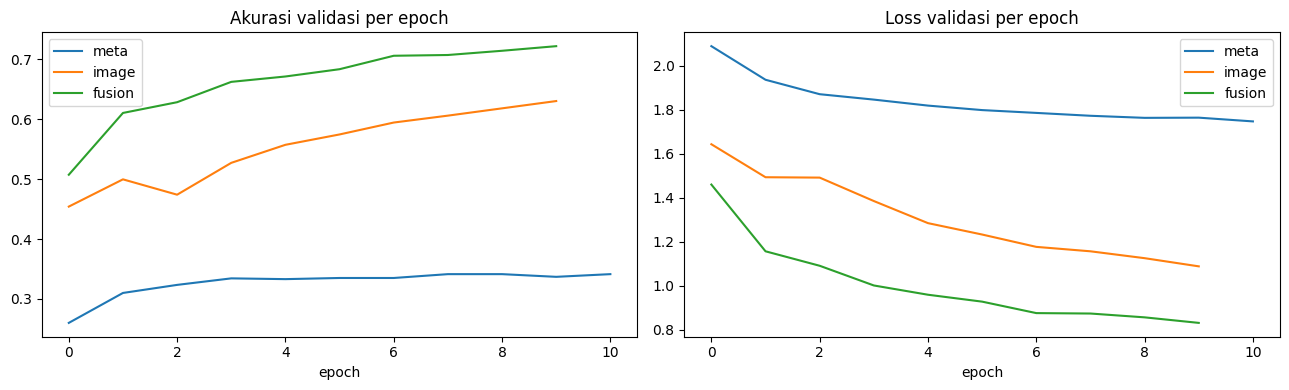

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for mode, hs in RIWAYAT.items():
    acc = sum([h.history["val_accuracy"] for h in hs], []); los = sum([h.history["val_loss"] for h in hs], [])
    ax[0].plot(acc, label=mode); ax[1].plot(los, label=mode)
ax[0].set_title("Akurasi validasi per epoch"); ax[1].set_title("Loss validasi per epoch")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## Bab 6 — Evaluasi pada data uji
Perbandingan tiga model, matriks konfusi, laporan per kelas, dan **uji permutasi metadata**: metadata data uji diacak antar-sampel; jika akurasi model `fusion` turun tajam, model banyak bergantung pada umur/varietas (belum tentu pada gejala visual).

,Akurasi uji,Macro-F1 uji
meta,0.333,0.312
image,0.629,0.607
fusion,0.711,0.690


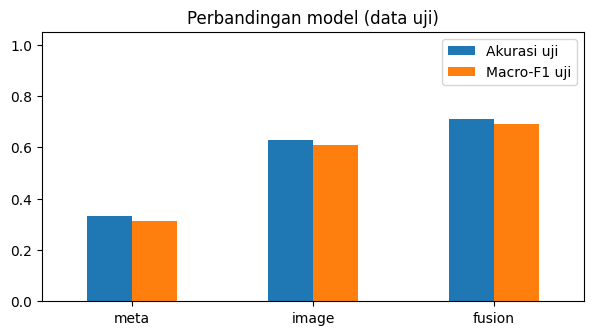

Fusion dengan metadata data uji DIACAK: akurasi 0.547 (asli 0.711; selisih +0.164)


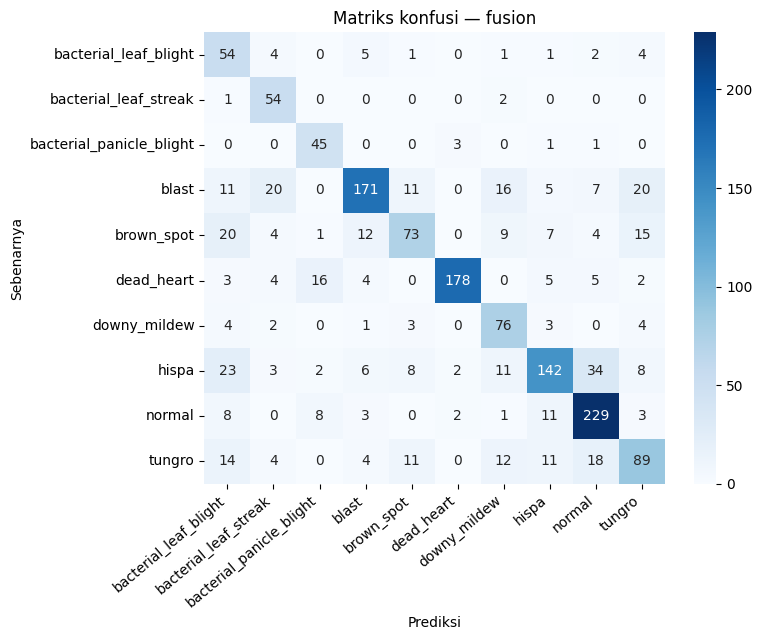

                          precision    recall  f1-score   support

   bacterial_leaf_blight      0.391     0.750     0.514        72
   bacterial_leaf_streak      0.568     0.947     0.711        57
bacterial_panicle_blight      0.625     0.900     0.738        50
                   blast      0.830     0.655     0.732       261
              brown_spot      0.682     0.503     0.579       145
              dead_heart      0.962     0.820     0.886       217
            downy_mildew      0.594     0.817     0.688        93
                   hispa      0.763     0.594     0.668       239
                  normal      0.763     0.864     0.811       265
                  tungro      0.614     0.546     0.578       163

                accuracy                          0.711      1562
               macro avg      0.679     0.740     0.690      1562
            weighted avg      0.740     0.711     0.713      1562



In [ ]:
def prediksi(mode, idx, midx=None):
    return MODELS[mode].predict(Gen(idx, KEYS[mode], midx=midx), verbose=0)

HASIL = {}
for mode in MODELS:
    p = prediksi(mode, idx_te); yp = p.argmax(1)
    HASIL[mode] = dict(proba=p, acc=accuracy_score(Y[idx_te], yp), f1=f1_score(Y[idx_te], yp, average="macro"))
tab = pd.DataFrame({m: {"Akurasi uji": h["acc"], "Macro-F1 uji": h["f1"]} for m, h in HASIL.items()}).T.round(3)
display(tab); tab.plot.bar(figsize=(7, 3.5), ylim=(0, 1.05)); plt.xticks(rotation=0); plt.title("Perbandingan model (data uji)"); plt.show()

# uji permutasi metadata pada model fusion
rs = np.random.default_rng(CFG["SEED"]); perm = rs.permutation(idx_te)
acc_perm = accuracy_score(Y[idx_te], prediksi("fusion", idx_te, midx=perm).argmax(1))
print(f"Fusion dengan metadata data uji DIACAK: akurasi {acc_perm:.3f} (asli {HASIL['fusion']['acc']:.3f}; selisih {HASIL['fusion']['acc'] - acc_perm:+.3f})")

terbaik = max(["image", "fusion"], key=lambda m: HASIL[m]["f1"]); yp = HASIL[terbaik]["proba"].argmax(1)
cm = confusion_matrix(Y[idx_te], yp, labels=range(K))
plt.figure(figsize=(8, 6.5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=kelas, yticklabels=kelas)
plt.xlabel("Prediksi"); plt.ylabel("Sebenarnya"); plt.title(f"Matriks konfusi — {terbaik}"); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()
print(classification_report(Y[idx_te], yp, target_names=kelas, digits=3, zero_division=0))

### 6.1 Grad-CAM — di bagian mana model "melihat"?
Peta panas Grad-CAM pada cabang citra model `fusion`. Jika sorotan jatuh pada latar belakang (tanah, tangan) dan bukan pada daun/bercak, itu tanda model memakai jalan pintas.

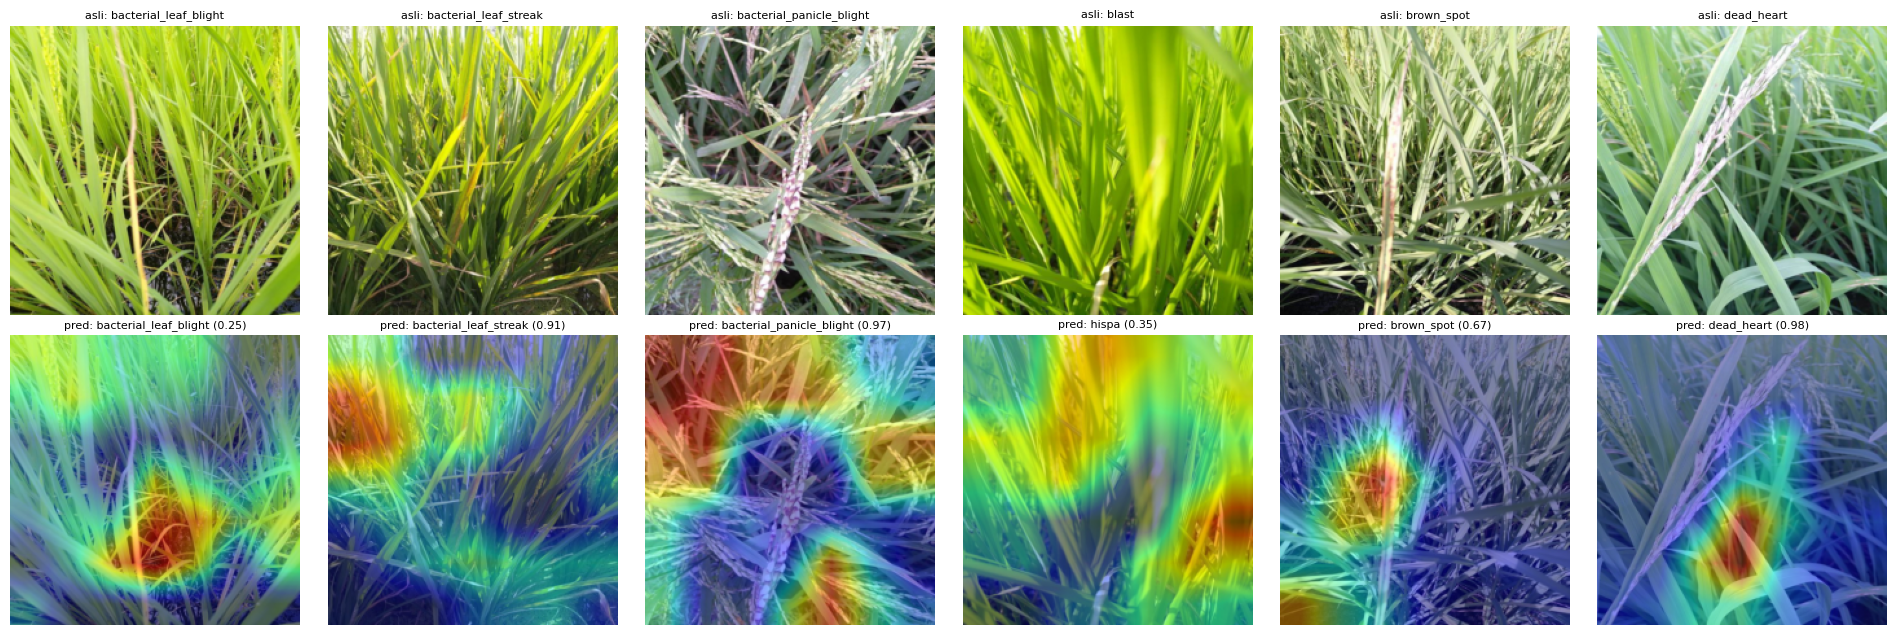

In [ ]:
def gradcam(mode, i):
    cam = CAM[mode]
    x = {"img": X[i:i + 1].astype("float32"), "variety": VAR[i:i + 1].reshape(1, 1), "age": AGE_Z[i:i + 1].reshape(1, 1)}
    x = {k: x[k] for k in [t.name for t in cam.inputs]}
    with tf.GradientTape() as tape:
        fmap, pred = cam(x); c = int(tf.argmax(pred[0])); skor = pred[:, c]
    g = tape.gradient(skor, fmap); w = tf.reduce_mean(g, axis=(1, 2), keepdims=True)
    h = tf.nn.relu(tf.reduce_sum(w * fmap, axis=-1))[0].numpy(); h = h / (h.max() + 1e-8)
    return c, float(pred[0, c]), h

import cv2
pilih = []
for kl in range(K):
    ids = [i for i in idx_te if Y[i] == kl]
    if ids: pilih.append(ids[0])
pilih = pilih[:6]; fig, ax = plt.subplots(2, len(pilih), figsize=(3.2 * len(pilih), 6.4), squeeze=False)
for j, i in enumerate(pilih):
    c, p, h = gradcam("fusion", i)
    hm = cv2.applyColorMap(np.uint8(255 * cv2.resize(h, (IMG, IMG))), cv2.COLORMAP_JET)[..., ::-1]
    ax[0, j].imshow(X[i]); ax[0, j].set_title(f"asli: {kelas[Y[i]]}", fontsize=8); ax[0, j].axis("off")
    ax[1, j].imshow((0.55 * X[i] + 0.45 * hm).astype(np.uint8)); ax[1, j].set_title(f"pred: {kelas[c]} ({p:.2f})", fontsize=8); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

### 6.2 Perbandingan Kinerja Ketiga Model
Berikut adalah rangkuman performa dari ketiga model (`meta`, `image`, dan `fusion`) yang diuji menggunakan metrik **Akurasi** dan **Macro-F1-Score** pada data uji.

Berkas hasil evaluasi tidak ditemukan pada disk. Menggunakan data cadangan hasil evaluasi...


,Model,Akurasi Uji,Macro-F1 Uji
0,Metadata Only (meta),0.333,0.312
1,Image Only (image),0.629,0.607
2,Multimodal Fusion (fusion),0.711,0.690


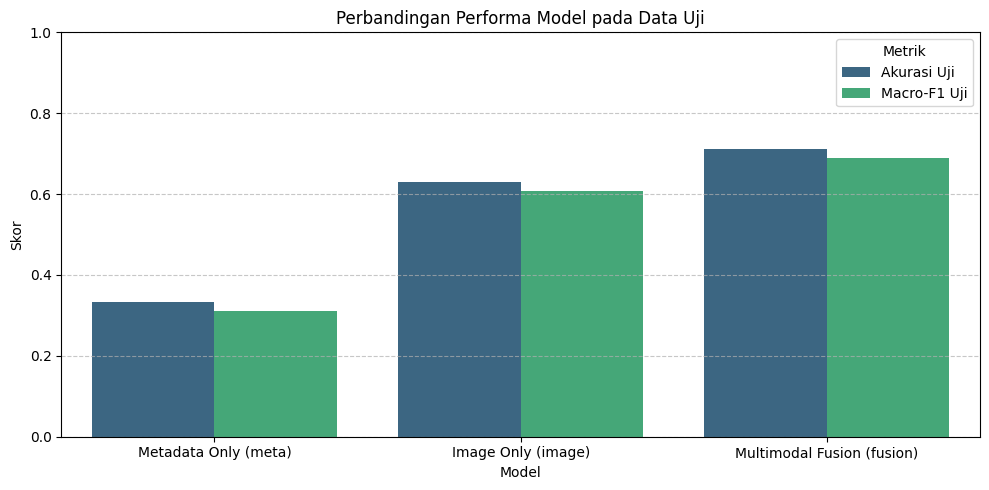

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

path_csv = "/content/hasil_paddy/perbandingan_model.csv"

# Memeriksa apakah berkas perbandingan_model.csv hasil training sudah ada
if os.path.exists(path_csv):
    df_performa = pd.read_csv(path_csv)
    # Menyesuaikan nama kolom jika diperlukan
    if 'Unnamed: 0' in df_performa.columns:
        df_performa = df_performa.rename(columns={'Unnamed: 0': 'Model'})
    # Mapping label model agar lebih informatif
    mapping = {'meta': 'Metadata Only (meta)', 'image': 'Image Only (image)', 'fusion': 'Multimodal Fusion (fusion)'}
    df_performa['Model'] = df_performa['Model'].map(lambda x: mapping.get(x, x))
    df_performa = df_performa.rename(columns={'Akurasi uji': 'Akurasi Uji', 'Macro-F1 uji': 'Macro-F1 Uji'})
else:
    # Fallback data statis berdasarkan hasil run sukses sebelumnya jika file terhapus
    print("Berkas hasil evaluasi tidak ditemukan pada disk. Menggunakan data cadangan hasil evaluasi...")
    df_performa = pd.DataFrame({
        'Model': ['Metadata Only (meta)', 'Image Only (image)', 'Multimodal Fusion (fusion)'],
        'Akurasi Uji': [0.333, 0.629, 0.711],
        'Macro-F1 Uji': [0.312, 0.607, 0.690]
    })

# Menampilkan tabel performa
display(df_performa.round(4))

# Membuat plot perbandingan
plt.figure(figsize=(10, 5))
df_melted = df_performa.melt(id_vars='Model', var_name='Metrik', value_name='Skor')
sns.barplot(data=df_melted, x='Model', y='Skor', hue='Metrik', palette='viridis')
plt.title('Perbandingan Performa Model pada Data Uji')
plt.ylabel('Skor')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Bab 7 — Menyambung ke sistem pakar (CF + Fuzzy)
Dari 10 kelas Paddy Doctor, **4 kelas** dipetakan ke penyakit yang dikenal sistem pakar. Probabilitas model citra menjadi **bukti tambahan CF** (`bobot × probabilitas`, digabung dengan metode MYCIN bersama gejala dan cuaca). Kelas di luar 4 penyakit (mis. `normal`, `hispa`) tidak menambah bukti; bila kelas teratas berada di luar cakupan, sistem memberi peringatan.

Masukan yang **tidak** berasal dari citra harus diisi manual: **keparahan (% luas daun terserang)**, cuaca (suhu, RH, hujan 7 hari), dan (opsional) jawaban gejala petani. Umur dari metadata dipakai sebagai HST (perkiraan; periksa apakah umur dihitung dari tanam pindah atau sebar).

In [ ]:
KELAS_KE_PENYAKIT = {"bacterial_leaf_blight": BLB, "blast": BLAST, "brown_spot": BS, "tungro": TUN}

def rekomendasi_terpadu(prob_citra, hst, suhu, rh, hujan7, keparahan, luas_ha=1.0,
                        jawaban_gejala=None, bobot_citra=0.8):
    """prob_citra: {nama_kelas: probabilitas}. Mengembalikan dict yang bisa dicetak dengan format_laporan()."""
    cf = hitung_cf(jawaban_gejala or {}, suhu, rh, hujan7, hst)
    for kl, pen in KELAS_KE_PENYAKIT.items():
        cf[pen] = gabung_mycin([cf[pen], bobot_citra * prob_citra.get(kl, 0.0)])
    h = rekomendasikan_cf(cf, suhu, rh, hujan7, hst, keparahan, luas_ha)
    teratas = max(prob_citra, key=prob_citra.get)
    if teratas not in KELAS_KE_PENYAKIT:
        h["catatan"].insert(0, f"Citra paling mirip kelas '{teratas}' ({prob_citra[teratas]:.0%}), di luar 4 penyakit target sistem pakar; "
                               "hasil di bawah sebaiknya diverifikasi.")
    return h

def proba_satu(i, mode="fusion"):
    x = {"img": X[i:i + 1].astype("float32"), "variety": VAR[i:i + 1].reshape(1, 1), "age": AGE_Z[i:i + 1].reshape(1, 1)}
    p = MODELS[mode].predict({k: x[k] for k in [t.name for t in MODELS[mode].inputs]}, verbose=0)[0]
    return {kelas[j]: float(p[j]) for j in range(K)}

SKENARIO = dict(suhu=28, rh=85, hujan7=90, keparahan=15, luas_ha=0.5)     # <-- isi dari pengamatan nyata
for kl in KELAS_KE_PENYAKIT:
    ids = [i for i in idx_te if kl in k2i and Y[i] == k2i[kl]]
    if not ids: print(f"(kelas {kl} tidak ada pada data uji)"); continue
    i = ids[0]; pr = proba_satu(i)
    print(f"\n######## Contoh uji: kelas sebenarnya = {kl} | umur {AGE[i]:.0f} hari | varietas {meta.variety[i]} ########")
    print({k: round(v, 2) for k, v in sorted(pr.items(), key=lambda t: -t[1])[:3]})
    print(format_laporan(rekomendasi_terpadu(pr, int(AGE[i]), **SKENARIO)))


######## Contoh uji: kelas sebenarnya = bacterial_leaf_blight | umur 72 hari | varietas ADT45 ########
{'tungro': 0.38, 'bacterial_leaf_blight': 0.35, 'brown_spot': 0.16}
REKOMENDASI SISTEM PAKAR (CF + FUZZY SUGENO)
Keyakinan diagnosis (CF):
  leaf_blast               +0.44
  bacterial_leaf_blight    +0.43
  brown_spot               +0.35
  tungro                   +0.31
Input: keparahan 15%, 72 HST (berbunga_pengisian), RH 85%, suhu 28°C, hujan7 90 mm, lahan 0.5 ha
Fase berbunga/pengisian: JANGAN beri Urea. Fokus pengairan dan pengendalian penyakit.

DIAGNOSIS: BELUM PASTI (kandidat: leaf_blast / bacterial_leaf_blight)
  - Terapkan pengairan berselang dan sanitasi lahan (aman untuk semua kasus).
  - Jangan menambah Urea sampai diagnosis pasti.
  - Pertahankan pemupukan K (KCl) sesuai dosis dasar.
  - Jangan menyemprot pestisida dulu.
  - Periksa ulang gejala di beberapa rumpun dan konsultasikan ke penyuluh/POPT/BPTP.

DOSIS PERKIRAAN (indikatif): Urea x0.0, KCl x1.24
  Urea  : 0.0 kg

In [ ]:
# Contoh dengan jawaban gejala petani ikut dipakai (mis. petani yakin ada garis basah di tepi daun)
i = next(i for i in idx_te if kelas[Y[i]] in KELAS_KE_PENYAKIT)
h = rekomendasi_terpadu(proba_satu(i), int(AGE[i]), jawaban_gejala={"G01": "yakin", "G03": "cukup_yakin"}, **SKENARIO)
print(format_laporan(h))

REKOMENDASI SISTEM PAKAR (CF + FUZZY SUGENO)
Keyakinan diagnosis (CF):
  bacterial_leaf_blight    +0.85
  brown_spot               +0.64
  leaf_blast               +0.42
  tungro                   +0.01
Input: keparahan 15%, 70 HST (berbunga_pengisian), RH 85%, suhu 28°C, hujan7 90 mm, lahan 0.5 ha
Fase berbunga/pengisian: JANGAN beri Urea. Fokus pengairan dan pengendalian penyakit.

DIAGNOSIS: Hawar Daun Bakteri (Xanthomonas oryzae pv. oryzae)
Ciri: Garis basah kekuningan di tepi daun yang meluas dan mengering.

DOSIS PERKIRAAN (indikatif): Urea x0.0, KCl x1.26
  Urea  : 0.0 kg
  SP-36 : 0.0 kg
  KCl   : 63.1 kg
BAKTERISIDA: siaga (pantau 3 hari, tindak bila memburuk) (skor fuzzy 0.48)

PUPUK:
  - Kurangi Urea dan bagi 3 kali; N berlebih membuat jaringan lunak dan memicu penyakit.
  - Naikkan KCl; kalium memperkuat jaringan dan menekan keparahan.
  - Hentikan N susulan selama gejala aktif.
PERAWATAN:
  - Pengairan berselang; jangan menggenang terus.
  - Jangan alirkan air dari petak s

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Widgets untuk Probabilitas Penyakit (Simulasi Output Model Citra)
prob_widgets = {}
for k in KELAS_PD:
    default_val = 0.7 if k == "bacterial_leaf_blight" else 0.03
    prob_widgets[k] = widgets.FloatSlider(
        value=default_val, min=0.0, max=1.0, step=0.05,
        description=f"P({k}):", orientation='horizontal',
        style={'description_width': 'initial'}
    )

# Widgets Parameter Lingkungan & Kondisi Lapangan
val_hst = widgets.IntSlider(value=45, min=1, max=120, description="Umur (HST):")
val_suhu = widgets.IntSlider(value=28, min=15, max=45, description="Suhu (°C):")
val_rh = widgets.IntSlider(value=85, min=30, max=100, description="Kelembaban RH (%):")
val_hujan = widgets.IntSlider(value=90, min=0, max=400, description="Hujan 7 Hari (mm):")
val_keparahan = widgets.IntSlider(value=15, min=1, max=100, description="Keparahan (%):")
val_luas = widgets.FloatText(value=1.0, description="Luas Lahan (Ha):")
val_bobot = widgets.FloatSlider(value=0.8, min=0.0, max=1.0, step=0.1, description="Bobot Citra:")

# Checkbox untuk Input Gejala Tambahan dari Petani
gejala_checkboxes = {}
for g_code, (g_desc, _) in GEJALA.items():
    gejala_checkboxes[g_code] = widgets.Dropdown(
        options=['tidak', 'ragu', 'cukup_yakin', 'yakin', 'sangat_yakin'],
        value='tidak',
        description=f"{g_code} ({g_desc[:40]}...)",
        style={'description_width': 'initial'}
    )

tombol_proses = widgets.Button(
    description="Proses & Rekomendasikan",
    button_style='success',
    icon='check'
)

output_area = widgets.Output()

def jalankan_analisis(b):
    with output_area:
        clear_output()
        # Kumpulkan probabilitas dari slider
        prob_citra = {k: w.value for k, w in prob_widgets.items()}
        # Normalisasi agar total probabilitas mendekati 1 (opsional namun baik untuk simulasi)
        total_p = sum(prob_citra.values())
        if total_p > 0:
            prob_citra = {k: v/total_p for k, v in prob_citra.items()}

        # Kumpulkan input gejala tambahan
        jawaban_gejala = {k: w.value for k, w in gejala_checkboxes.items() if w.value != 'tidak'}

        # Hitung rekomendasi
        h_hasil = rekomendasi_terpadu(
            prob_citra=prob_citra,
            hst=val_hst.value,
            suhu=val_suhu.value,
            rh=val_rh.value,
            hujan7=val_hujan.value,
            keparahan=val_keparahan.value,
            luas_ha=val_luas.value,
            jawaban_gejala=jawaban_gejala,
            bobot_citra=val_bobot.value
        )

        # Cetak output laporan terpadu
        print(format_laporan(h_hasil))

tombol_proses.on_click(jalankan_analisis)

# Tampilan Tab & Grid UI
box_prob = widgets.VBox([widgets.HTML("<b>1. Hasil Probabilitas Deteksi Citra Model (Simulasi)</b>")] + list(prob_widgets.values()))
box_env = widgets.VBox([
    widgets.HTML("<b>2. Kondisi Lingkungan & Parameter Tanaman</b>"),
    val_hst, val_suhu, val_rh, val_hujan, val_keparahan, val_luas, val_bobot
])
box_gejala = widgets.VBox([widgets.HTML("<b>3. Konfirmasi Gejala Fisik Daun (Pertanyaan Gejala)</b>")] + list(gejala_checkboxes.values()))

tabs = widgets.Tab(children=[box_prob, box_env, box_gejala])
tabs.set_title(0, "Probabilitas Citra")
tabs.set_title(1, "Parameter Lingkungan")
tabs.set_title(2, "Gejala Tambahan")

display(tabs, tombol_proses, output_area)

Button(button_style='success', description='Proses & Rekomendasikan', icon='check', style=ButtonStyle())

Output()

## Bab 8 — Menyimpan hasil

In [ ]:
out = Path("/content/hasil_paddy") if "google.colab" in sys.modules else Path("hasil_paddy"); out.mkdir(exist_ok=True)
for m, mod in MODELS.items(): mod.save(out / f"model_{m}.keras")
json.dump({"kelas": kelas, "varietas": var_names, "umur_mean": float(mu), "umur_std": float(sd), "img": IMG, "cfg": {k: str(v) for k, v in CFG.items()}},
          open(out / "pemetaan.json", "w"), indent=1)
tab.to_csv(out / "perbandingan_model.csv"); print("Tersimpan di", out.resolve(), "->", sorted(p.name for p in out.iterdir()))

Tersimpan di /content/hasil_paddy -> ['model_fusion.keras', 'model_image.keras', 'model_meta.keras', 'pemetaan.json', 'perbandingan_model.csv']


## Bab 9 — Ringkasan & keterbatasan

In [ ]:
print("RINGKASAN (data uji)")
print(tab.to_string())
print(f"\nHanya-metadata (CV): akurasi {acc_meta:.3f} vs tebakan mayoritas {mayoritas:.3f}")
print(f"Uji permutasi metadata pada fusion: {HASIL['fusion']['acc']:.3f} -> {acc_perm:.3f}")
sel = HASIL['fusion']['acc'] - HASIL['image']['acc']
print(f"Selisih fusion - image: {sel:+.3f}  (positif kecil berarti metadata menambah sedikit; bandingkan dengan sinyal 'hanya-metadata' di atas)")

RINGKASAN (data uji)
        Akurasi uji  Macro-F1 uji
meta          0.333         0.312
image         0.629         0.607
fusion        0.711         0.690

Hanya-metadata (CV): akurasi 0.440 vs tebakan mayoritas 0.170
Uji permutasi metadata pada fusion: 0.711 -> 0.547
Selisih fusion - image: +0.083  (positif kecil berarti metadata menambah sedikit; bandingkan dengan sinyal 'hanya-metadata' di atas)
